# TP 6 — Régression linéaire : la consommation des voitures

---
##  Contexte et objectif du TP
Dans les TP précédents on prédisait une **catégorie** (toxique / comestible, espèce, chiffre) : c'était de la **classification**.
Ici on prédit un **nombre** : la **consommation d'une voiture en litres aux 100 km**, à partir de ses caractéristiques
(poids, puissance, cylindrée, accélération, année, origine). C'est de la **régression**.

Le jeu **Auto MPG** (UCI, 1993) décrit **398 voitures** vendues aux États-Unis entre 1970 et 1982. Les chocs pétroliers de 1973 et
1979 ont forcé les constructeurs à réduire la consommation : cela se voit dans les données.

Ce TP a pour but de :
1. comprendre la **régression simple** (une variable) en calculant la droite **à la main** (pente et ordonnée) ;
2. **mesurer l'erreur** d'un modèle avec le **RMSE** et le **R²**, et la comparer à un modèle naïf ;
3. passer à la **régression multiple** (plusieurs variables, dont une catégorielle) ;
4. **lire les coefficients** pour comprendre ce qui fait varier la consommation ;
5. examiner les **résidus** pour voir les **limites** du modèle linéaire ;
6. refaire l'expérience avec **Orange**.

| Partie | Contenu | Points |
|---|---|---|
| **A** | Explorer | 3 |
| **B** | Régression avec Python | 13 |
| **C** | Régression avec Orange | 4 |

##  Rappel : moindres carrés et mesures d'erreur
* Modèle simple : **ŷ = a·x + b** avec **a = cov(x, y) / var(x)** et **b = ȳ − a·x̄**
  (la droite qui rend la somme des carrés des erreurs la plus petite possible).
* **RMSE** = √( (1/n) Σ (yᵢ − ŷᵢ)² ) : l'**erreur typique**, exprimée dans l'**unité de la cible** (ici des L/100 km).
* **R²** = 1 − Σ (yᵢ − ŷᵢ)² / Σ (yᵢ − ȳ)² : part de la **variance expliquée** (1 = parfait, 0 = pas mieux que prédire la moyenne).

##  Livrables
Ce notebook exécuté (`.ipynb`) et le fichier Orange (`.ows`).

## 📖 Mini-glossaire
| Terme | Signification | Pourquoi on en a besoin |
|---|---|---|
| **Importation** | Charger bibliothèques et fichier | Point de départ |
| **Exploration / Visualisation** | Résumer et tracer les données | Comprendre avant de modéliser |
| **Imputation** | Remplacer une valeur manquante (ici par la **médiane**) | Le modèle ne sait pas calculer avec des cases vides ; la médiane résiste aux valeurs extrêmes |
| **Corrélation** | Nombre entre −1 et 1 : force de la relation linéaire entre deux variables | Repérer les variables prometteuses |
| **Séparation train/test (80/20)** | 80 % pour apprendre, 20 % pour évaluer | Mesurer la qualité sur des voitures jamais vues |
| **Entraînement (fit)** | Calculer les coefficients (pente, ordonnée…) sur le train | C'est l'apprentissage |
| **Prédiction** | Calculer ŷ pour de nouvelles voitures | Utiliser le modèle |
| **RMSE / R²** | Erreur typique / part de variance expliquée | Mesurer la qualité d'un modèle de régression |
| **Modèle naïf** | Prédire toujours la moyenne du train | Score plancher : le modèle doit faire mieux |
| **One-hot (`drop_first`)** | Transformer une variable catégorielle en colonnes 0/1, en retirant une colonne | Les modèles ne lisent que des nombres ; `drop_first` évite la redondance entre colonnes |
| **Standardisation + Pipeline** | Mettre les variables à la même échelle, enchaînées proprement avec le modèle | Rendre les coefficients **comparables** |
| **Résidu** | Erreur d'une prédiction : y − ŷ | Si les résidus montrent une forme, le modèle rate quelque chose |

## 0. Importation des bibliothèques et du fichier

**Importation** : `numpy`/`pandas` (calcul et tableaux), `matplotlib` (graphiques) et `scikit-learn` :
`LinearRegression` (le modèle), `train_test_split` (séparation), `StandardScaler`/`ColumnTransformer`/`Pipeline`
(standardisation propre), `mean_squared_error`/`r2_score` (mesures d'erreur).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option("display.max_columns", 30)
print("Bibliothèques importées ✅")

Bibliothèques importées ✅


**Importation du fichier** : sur Colab, il faut envoyer `voitures.csv` depuis votre ordinateur
(en Jupyter local, placez-le dans le même dossier que le notebook).

---
# PARTIE A — Explorer · *3 points*
**But** : connaître les données, traiter les valeurs manquantes et repérer quelles variables sont liées à la consommation.

## A.1 — Premier contact
### Importation et exploration
*Pourquoi ?* Vérifier les colonnes, les types, les valeurs manquantes et l'ordre de grandeur de la cible.

In [2]:
df = pd.read_csv("voitures.csv")                      # importation
print("Dimensions :", df.shape)
display(df.head())
print("\nTypes :\n", df.dtypes)

CIBLE = "consommation_l100"                           # ⚠️ adapter si le nom diffère
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

Dimensions : (398, 9)


,nom,consommation_l100,cylindres,cylindree_cm3,puissance_ch,poids_kg,acceleration_s,annee,origine
0,chevrolet chevelle malibu,13.07,8,5031,130.0,1589,12.0,1970,Etats-Unis
1,buick skylark 320,15.68,8,5735,165.0,1675,11.5,1970,Etats-Unis
2,plymouth satellite,13.07,8,5211,150.0,1559,11.0,1970,Etats-Unis
3,amc rebel sst,14.70,8,4982,150.0,1557,12.0,1970,Etats-Unis
4,ford torino,13.84,8,4949,140.0,1564,10.5,1970,Etats-Unis



Types :
 nom                   object
consommation_l100    float64
cylindres              int64
cylindree_cm3          int64
puissance_ch         float64
poids_kg               int64
acceleration_s       float64
annee                  int64
origine               object
dtype: object

Valeurs manquantes par colonne :
nom                  0
consommation_l100    0
cylindres            0
cylindree_cm3        0
puissance_ch         6
poids_kg             0
acceleration_s       0
annee                0
origine              0
dtype: int64


### Consommation : moyenne, minimum, maximum

Consommation moyenne : 11.21 L/100 km
Consommation minimale : 5.05 L/100 km
Consommation maximale : 26.14 L/100 km


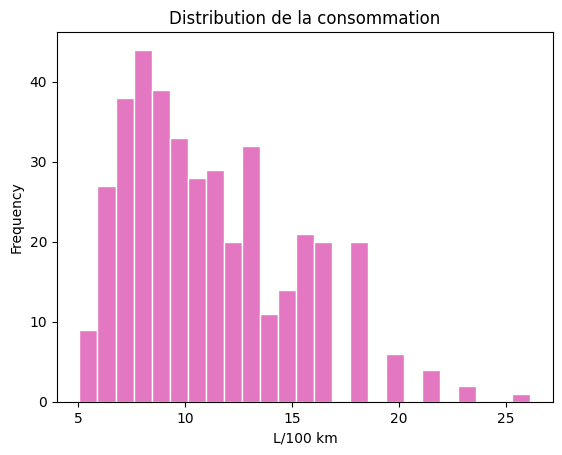

In [3]:
print(f"Consommation moyenne : {df[CIBLE].mean():.2f} L/100 km")
print(f"Consommation minimale : {df[CIBLE].min():.2f} L/100 km")
print(f"Consommation maximale : {df[CIBLE].max():.2f} L/100 km")

df[CIBLE].plot(kind="hist", bins=25, color="tab:pink", edgecolor="white")
plt.title("Distribution de la consommation")
plt.xlabel("L/100 km")
plt.show()

### Remplacer les puissances manquantes par la médiane
**Imputation** : on remplace chaque puissance manquante par la **médiane** de la colonne (la valeur « du milieu »).
*Pourquoi la médiane ?* Elle est peu influencée par les voitures très puissantes (valeurs extrêmes), contrairement à la moyenne.

> Remarque : on calcule ici la médiane sur tout le jeu, comme le demande l'énoncé. Dans un projet rigoureux, on la calculerait
> sur le **train seul** puis on l'appliquerait au test, pour ne rien laisser « fuir » du test vers l'entraînement.

In [4]:
PUISSANCE = "puissance_ch"
mediane = df[PUISSANCE].median()
print(f"Médiane de la puissance : {mediane} ch | manquantes avant : {df[PUISSANCE].isna().sum()}")

df[PUISSANCE] = df[PUISSANCE].fillna(mediane)
print("Manquantes après :", df[PUISSANCE].isna().sum())

Médiane de la puissance : 93.5 ch | manquantes avant : 6
Manquantes après : 0


✍️ **Ma réponse A.1** : valeurs manquantes = *(…, dans la colonne …)* ; consommation moyenne = *(…)*, minimale = *(…)*,
maximale = *(…)* L/100 km ; les puissances manquantes ont été remplacées par la médiane = *(…)* ch.

## A.2 — Corrélations
La **corrélation** de Pearson mesure la relation **linéaire** entre deux variables : proche de +1 ou −1 = forte, proche de 0 = faible.
On la calcule entre chaque variable numérique et la consommation, puis on trace la consommation en fonction du poids.

poids_kg          0.885
cylindree_cm3     0.867
puissance_ch      0.853
cylindres         0.839
acceleration_s   -0.456
annee            -0.557
Name: consommation_l100, dtype: float64


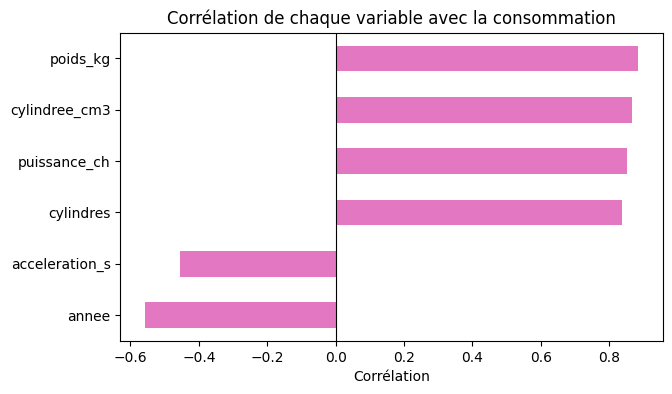

In [5]:
numeriques = df.select_dtypes(include="number").columns.tolist()
corr = df[numeriques].corr()[CIBLE].drop(CIBLE).sort_values(ascending=False)
print(corr.round(3))

corr.sort_values().plot(kind="barh", color="tab:pink", figsize=(7, 4))
plt.title("Corrélation de chaque variable avec la consommation")
plt.xlabel("Corrélation")
plt.axvline(0, color="black", lw=0.8)
plt.show()

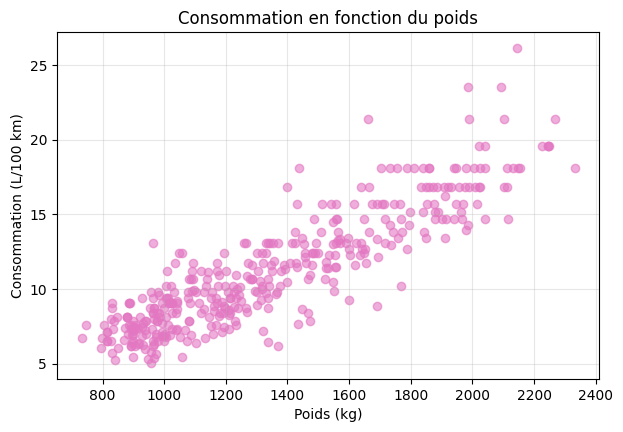

In [6]:
POIDS = "poids_kg"
plt.figure(figsize=(7, 4.5))
plt.scatter(df[POIDS], df[CIBLE], alpha=0.6, color="tab:pink")
plt.xlabel("Poids (kg)"); plt.ylabel("Consommation (L/100 km)")
plt.title("Consommation en fonction du poids")
plt.grid(alpha=0.3)
plt.show()

✍️ **Ma réponse A.2** : la variable la plus corrélée à la consommation est *(…)* (r = …) ; le poids a une corrélation de *(…)*.
**La relation est-elle linéaire ?** *(regarder le nuage : globalement croissante, mais le nuage est-il légèrement
courbé ? la dispersion augmente-t-elle avec le poids ? → à relier aux résidus de B.5)*.

---
# PARTIE B — Régression avec Python · *13 points*

## B.1 — À la main
### Séparation train / test (80 % / 20 %)
* **Train (80 %)** : sert à calculer la droite.
* **Test (20 %)** : gardé de côté pour mesurer l'erreur sur des voitures **jamais vues**.
* `random_state=42` : découpe **reproductible**.

On sépare **une seule fois le tableau complet** : toutes les questions suivantes réutiliseront exactement les mêmes voitures
de test, ce qui rend les comparaisons équitables.

In [7]:
df_train, df_test = train_test_split(df, test_size=0.20, random_state=42)
print("Train :", df_train.shape, "| Test :", df_test.shape)

x_train = df_train[POIDS].values
y_train = df_train[CIBLE].values
x_test = df_test[POIDS].values
y_test = df_test[CIBLE].values

Train : (318, 9) | Test : (80, 9)


### Calcul de la pente et de l'ordonnée avec numpy
Formules des **moindres carrés** (sur le train) :
* **a = cov(x, y) / var(x)** (la pente) ;
* **b = ȳ − a·x̄** (l'ordonnée à l'origine : la droite passe toujours par le point moyen).

In [8]:
x_moy, y_moy = x_train.mean(), y_train.mean()

# covariance et variance (même facteur 1/n au numérateur et au dénominateur : il s'annule)
a = np.sum((x_train - x_moy) * (y_train - y_moy)) / np.sum((x_train - x_moy) ** 2)
b = y_moy - a * x_moy
print(f"Pente a            = {a:.6f}  L/100 km par kg")
print(f"Ordonnée b         = {b:.4f}  L/100 km")
print(f"Droite : consommation = {a:.5f} × poids + {b:.3f}")

# Vérification avec scikit-learn
lr = LinearRegression().fit(x_train.reshape(-1, 1), y_train)
print(f"\nscikit-learn : a = {lr.coef_[0]:.6f} | b = {lr.intercept_:.4f}")
print("Identique à la main :", np.isclose(a, lr.coef_[0]) and np.isclose(b, lr.intercept_))
print(f"\n➡️ Pour 100 kg de plus : +{a * 100:.3f} L/100 km")

Pente a            = 0.009016  L/100 km par kg
Ordonnée b         = -0.9559  L/100 km
Droite : consommation = 0.00902 × poids + -0.956

scikit-learn : a = 0.009016 | b = -0.9559
Identique à la main : True

➡️ Pour 100 kg de plus : +0.902 L/100 km


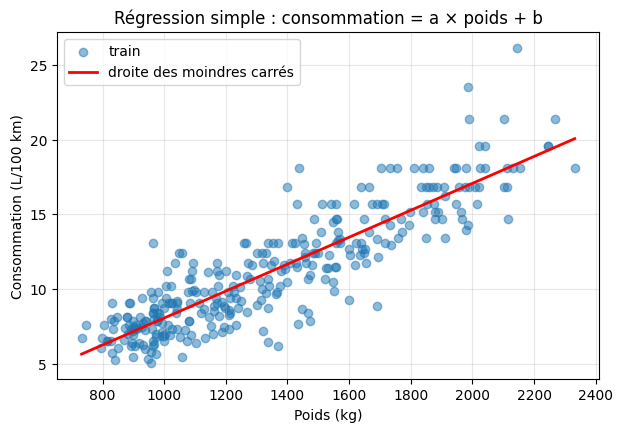

In [9]:
# Visualisation de la droite sur le nuage de points (train)
xs = np.linspace(x_train.min(), x_train.max(), 100)
plt.figure(figsize=(7, 4.5))
plt.scatter(x_train, y_train, alpha=0.5, label="train")
plt.plot(xs, a * xs + b, color="red", lw=2, label="droite des moindres carrés")
plt.xlabel("Poids (kg)"); plt.ylabel("Consommation (L/100 km)")
plt.legend(); plt.grid(alpha=0.3)
plt.title("Régression simple : consommation = a × poids + b")
plt.show()

✍️ **Ma réponse B.1** : a = *(…)*, b = *(…)* ; vérification scikit-learn : *(identique)*.
**Signification de la pente pour 100 kg de plus** : en moyenne, une voiture plus lourde de 100 kg consomme *(a × 100 = …)* L/100 km
de plus. **L'ordonnée b** est la valeur théorique pour un poids de 0 kg : elle n'a pas de sens physique, c'est juste le point de départ de la droite.

## B.2 — Mesurer l'erreur
On évalue le modèle simple sur le **test** avec **RMSE** (erreur typique en L/100 km) et **R²** (part de variance expliquée).

On compare à un **modèle naïf** qui prédit **toujours la consommation moyenne du train**.
*Pourquoi ?* C'est le « score plancher » : un modèle qui n'est pas meilleur que la moyenne n'a aucune utilité.

In [10]:
def evaluer(y_vrai, y_pred):
    """Retourne (RMSE, R2) calculés à la main pour bien voir les formules."""
    rmse = np.sqrt(np.mean((y_vrai - y_pred) ** 2))
    r2 = 1 - np.sum((y_vrai - y_pred) ** 2) / np.sum((y_vrai - y_vrai.mean()) ** 2)
    return rmse, r2

# Modèle simple (droite calculée en B.1)
pred_simple = a * x_test + b
rmse_s, r2_s = evaluer(y_test, pred_simple)

# Modèle naïf : toujours la moyenne du train
pred_naif = np.full_like(y_test, y_train.mean(), dtype=float)
rmse_n, r2_n = evaluer(y_test, pred_naif)

# Contrôle avec scikit-learn
print("Contrôle sklearn :",
      np.isclose(rmse_s, np.sqrt(mean_squared_error(y_test, pred_simple))),
      np.isclose(r2_s, r2_score(y_test, pred_simple)))

resume = pd.DataFrame({"RMSE (L/100 km)": [rmse_n, rmse_s], "R²": [r2_n, r2_s]},
                      index=["Modèle naïf (moyenne)", "Régression simple (poids)"]).round(3)
display(resume)

Contrôle sklearn : True True


,RMSE (L/100 km),R²
Modèle naïf (moyenne),3.918,-0.001
Régression simple (poids),1.729,0.805


✍️ **Ma réponse B.2** : RMSE = *(…)* et R² = *(…)* pour le modèle simple ; naïf : RMSE = *(…)*, R² ≈ *(0, voire légèrement négatif)*.
Le poids seul explique *(…)* % de la variance de la consommation, et l'erreur typique tombe de *(…)* à *(…)* L/100 km.

## B.3 — Régression multiple
On utilise **plusieurs variables** : `poids_kg`, `puissance_ch`, `cylindree_cm3`, `acceleration_s`, `annee` et `origine`.

`origine` est une variable **catégorielle** (texte ou code de pays) : on la transforme par **one-hot** avec `drop_first=True`.
Chaque pays devient une colonne 0/1, et on **retire la première** (elle devient la **référence**) : sans cela, les colonnes seraient
redondantes (si on sait que ce n'est ni A ni B, c'est forcément C), ce qui perturbe un modèle linéaire.

In [11]:
NUM = ["poids_kg", "puissance_ch", "cylindree_cm3", "acceleration_s", "annee"]   # ⚠️ adapter aux noms exacts
df_m = df[NUM].copy()
df_m["origine"] = df["origine"].astype(str)            # astype(str) : fonctionne si l'origine est codée 1/2/3 comme si elle est en texte

X_all = pd.get_dummies(df_m, columns=["origine"], drop_first=True, dtype=float)
print("Colonnes du modèle :", list(X_all.columns))

X_train_m, X_test_m = X_all.loc[df_train.index], X_all.loc[df_test.index]   # mêmes voitures qu'en B.1
y_train_m, y_test_m = df_train[CIBLE], df_test[CIBLE]

Colonnes du modèle : ['poids_kg', 'puissance_ch', 'cylindree_cm3', 'acceleration_s', 'annee', 'origine_Europe', 'origine_Japon']


**Entraînement** puis **test** :

In [12]:
multi = LinearRegression().fit(X_train_m, y_train_m)         # ENTRAÎNEMENT
pred_multi = multi.predict(X_test_m)                         # PRÉDICTION sur le test
rmse_m, r2_m = evaluer(y_test_m.values, pred_multi)

comparaison = pd.DataFrame(
    {"RMSE (L/100 km)": [rmse_n, rmse_s, rmse_m], "R²": [r2_n, r2_s, r2_m]},
    index=["Modèle naïf", "Régression simple (poids)", "Régression multiple"]).round(3)
display(comparaison)
print(f"Baisse du RMSE : {rmse_s:.3f} -> {rmse_m:.3f} L/100 km  ({(1 - rmse_m / rmse_s) * 100:.1f} %)")

,RMSE (L/100 km),R²
Modèle naïf,3.918,-0.001
Régression simple (poids),1.729,0.805
Régression multiple,1.428,0.867


Baisse du RMSE : 1.729 -> 1.428 L/100 km  (17.4 %)


✍️ **Ma réponse B.3** : RMSE = *(…)* ; R² = *(…)* ; par rapport au modèle simple (RMSE …, R² …) le gain est *(important / modéré)* :
*(le RMSE baisse de … %, le R² passe de … à …)*. Cela s'explique par *(l'année et la puissance apportent de l'information que le poids seul n'a pas)*.

## B.4 — Lire les coefficients
Dans le modèle précédent, les coefficients **ne sont pas comparables** : un coefficient est « litres par unité de la variable »,
et les unités diffèrent (kg, ch, secondes, années…). Pour comparer, on **standardise** les variables numériques
(moyenne 0, écart-type 1) : chaque coefficient devient « variation de consommation pour **+1 écart-type** de la variable ».

On utilise un **Pipeline** : il enchaîne standardisation puis régression et garantit que la standardisation est
apprise **sur le train seulement**, puis appliquée telle quelle au test.

Coefficients (variables numériques standardisées) :
poids_kg          2.244
annee            -1.175
puissance_ch      1.043
origine_Europe   -0.756
origine_Japon    -0.419
acceleration_s    0.226
cylindree_cm3    -0.155
dtype: float64

Ordonnée à l'origine (consommation moyenne prédite) : 11.406


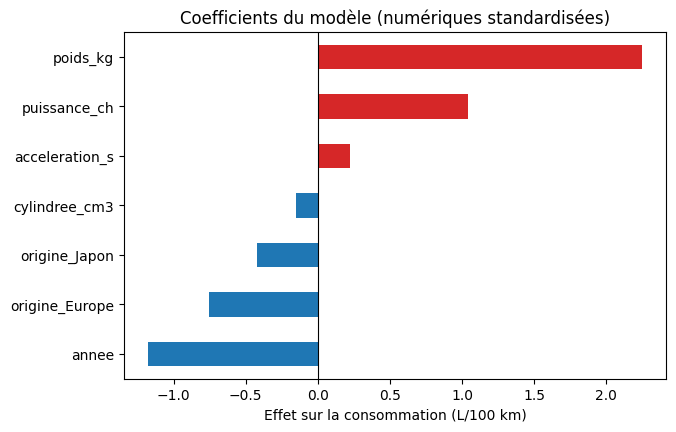

Pipeline : RMSE = 1.428 | R² = 0.867  (identique au modèle B.3)


In [13]:
prepro = ColumnTransformer(
    [("std", StandardScaler(), NUM)],        # standardise les variables numériques
    remainder="passthrough")                 # laisse les colonnes one-hot (0/1) telles quelles

pipe = Pipeline([("prepro", prepro), ("modele", LinearRegression())])
pipe.fit(X_train_m, y_train_m)

# Après ColumnTransformer, l'ordre des colonnes = NUM puis le reste
noms = NUM + [c for c in X_train_m.columns if c not in NUM]
coefs = pd.Series(pipe.named_steps["modele"].coef_, index=noms)

print("Coefficients (variables numériques standardisées) :")
print(coefs.round(3).sort_values(key=abs, ascending=False))
print(f"\nOrdonnée à l'origine (consommation moyenne prédite) : {pipe.named_steps['modele'].intercept_:.3f}")

coefs.sort_values().plot(kind="barh", color=["tab:red" if v > 0 else "tab:blue" for v in coefs.sort_values()], figsize=(7, 4.5))
plt.axvline(0, color="black", lw=0.8)
plt.title("Coefficients du modèle (numériques standardisées)")
plt.xlabel("Effet sur la consommation (L/100 km)")
plt.show()

# Les prédictions ne changent pas : la standardisation ne modifie pas la qualité d'une régression linéaire
rmse_p, r2_p = evaluer(y_test_m.values, pipe.predict(X_test_m))
print(f"Pipeline : RMSE = {rmse_p:.3f} | R² = {r2_p:.3f}  (identique au modèle B.3)")

✍️ **Ma réponse B.4** :
* Les variables qui pèsent le plus (plus grand |coefficient|) : *(…)*, puis *(…)*.
* **Signe du coefficient de `annee`** : *(négatif : à poids, puissance, etc. égaux, une voiture plus récente consomme moins ;
  c'est l'effet des chocs pétroliers de 1973 et 1979 et des progrès techniques)*.
* Les coefficients des colonnes `origine` se lisent **par rapport à l'origine de référence** (celle retirée par `drop_first`).
* ⚠️ Poids, puissance et cylindrée sont **corrélés entre eux** : leurs coefficients individuels sont à interpréter avec prudence
  (colinéarité) ; le modèle est bon pour **prédire**, moins pour attribuer l'effet à une seule variable.

## B.5 — Résidus
Le **résidu** d'une voiture est **y − ŷ** (réel moins prédit). Deux graphiques diagnostiquent le modèle :
1. **Prédit vs réel** : si le modèle est parfait, tous les points sont sur la diagonale ;
2. **Résidus vs prédit** : on doit voir un nuage **sans forme** autour de 0. Une **courbe** ou un **entonnoir** signale une limite
   du modèle linéaire (relation non linéaire, variance non constante).

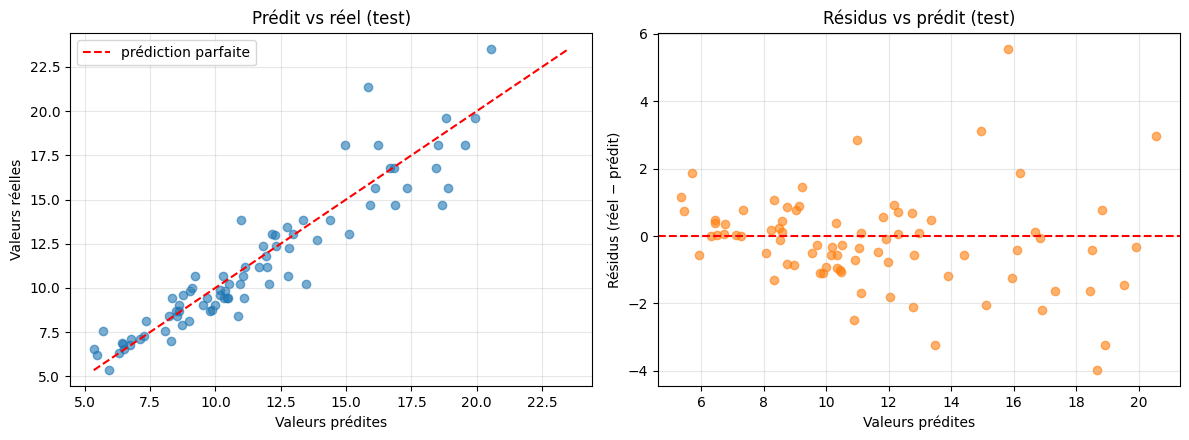

In [14]:
residus = y_test_m.values - pred_multi

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(pred_multi, y_test_m, alpha=0.6)
lim = [min(pred_multi.min(), y_test_m.min()), max(pred_multi.max(), y_test_m.max())]
ax[0].plot(lim, lim, color="red", ls="--", label="prédiction parfaite")
ax[0].set_xlabel("Valeurs prédites"); ax[0].set_ylabel("Valeurs réelles")
ax[0].set_title("Prédit vs réel (test)"); ax[0].legend()

ax[1].scatter(pred_multi, residus, alpha=0.6, color="tab:orange")
ax[1].axhline(0, color="red", ls="--")
ax[1].set_xlabel("Valeurs prédites"); ax[1].set_ylabel("Résidus (réel − prédit)")
ax[1].set_title("Résidus vs prédit (test)")
for a_ in ax: a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Modéliser le logarithme de la consommation
Si l'erreur grandit avec la consommation (forme d'entonnoir) ou si la relation est courbée, on peut modéliser **log(y)** :
cela « tasse » les grandes valeurs. Pour une comparaison **équitable**, on revient à l'échelle d'origine
(`np.exp`) avant de calculer RMSE et R² **sur le même test**.

,RMSE (L/100 km),R²
Modèle sur y,1.428,0.867
Modèle sur log(y),1.555,0.842


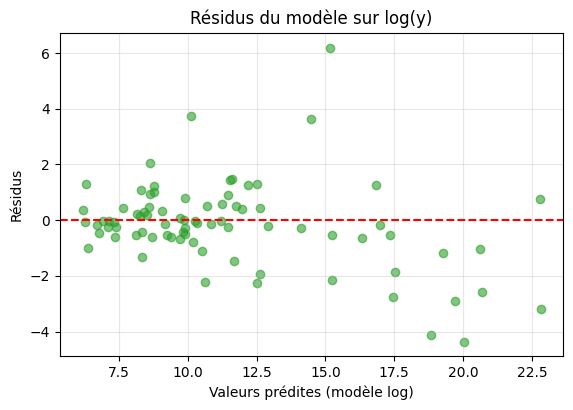

In [15]:
modele_log = LinearRegression().fit(X_train_m, np.log(y_train_m))      # on apprend log(consommation)
pred_log = np.exp(modele_log.predict(X_test_m))                         # retour à l'échelle L/100 km
rmse_l, r2_l = evaluer(y_test_m.values, pred_log)

display(pd.DataFrame({"RMSE (L/100 km)": [rmse_m, rmse_l], "R²": [r2_m, r2_l]},
                     index=["Modèle sur y", "Modèle sur log(y)"]).round(3))

residus_log = y_test_m.values - pred_log
plt.figure(figsize=(6.5, 4.2))
plt.scatter(pred_log, residus_log, alpha=0.6, color="tab:green")
plt.axhline(0, color="red", ls="--")
plt.xlabel("Valeurs prédites (modèle log)"); plt.ylabel("Résidus")
plt.title("Résidus du modèle sur log(y)")
plt.grid(alpha=0.3); plt.show()

✍️ **Ma réponse B.5** : *(forme visible dans les résidus ? ex. légère courbure, résidus plus grands pour les fortes consommations)*.
Modèle log : RMSE = *(…)*, R² = *(…)* contre *(…)* et *(…)* pour le modèle sur y → il est *(meilleur / équivalent / moins bon)* sur le test.
Interprétation : *(le log réduit la courbure et stabilise la dispersion, car l'effet des variables est plutôt **proportionnel** à la consommation)*.

## B.6 — Prédire
On prédit la consommation d'une **voiture européenne de 1980** : 1 050 kg, 75 ch, 1 600 cm³, 0 à 100 km/h en 15 s.

Pour que le modèle comprenne cette voiture, il faut lui donner **exactement les mêmes colonnes** qu'à l'entraînement
(y compris les colonnes one-hot de l'origine) : la cellule ci-dessous construit cette ligne automatiquement.

In [16]:
# L'année est-elle codée sur 2 chiffres (80) ou 4 chiffres (1980) dans le fichier ?
annee_voiture = 80 if df["annee"].max() < 100 else 1980

# Trouver l'étiquette "Europe" parmi les valeurs d'origine (⚠️ à ajuster si besoin)
valeurs_origine = sorted(df["origine"].astype(str).unique())
print("Valeurs possibles de l'origine :", valeurs_origine)
europe = next((v for v in valeurs_origine if "eur" in v.lower()), "2")   # en codage 1/2/3, 2 = Europe dans Auto MPG
print("Étiquette utilisée pour l'Europe :", europe)

nouvelle = {"poids_kg": 1050, "puissance_ch": 75, "cylindree_cm3": 1600,
            "acceleration_s": 15, "annee": annee_voiture}
ligne = pd.DataFrame([nouvelle])
for col in X_train_m.columns:                      # colonnes one-hot : 1 pour l'origine choisie, 0 sinon
    if col.startswith("origine_"):
        ligne[col] = 1.0 if col == f"origine_{europe}" else 0.0
ligne = ligne[X_train_m.columns]                   # même ordre de colonnes qu'à l'entraînement
display(ligne)

pred_voiture = multi.predict(ligne)[0]
pred_voiture_log = float(np.exp(modele_log.predict(ligne))[0])
print(f"Consommation prédite (modèle multiple)  : {pred_voiture:.2f} L/100 km")
print(f"Consommation prédite (modèle log)       : {pred_voiture_log:.2f} L/100 km")
print(f"Fourchette indicative (± 1 RMSE)        : {pred_voiture - rmse_m:.1f} à {pred_voiture + rmse_m:.1f} L/100 km")

Valeurs possibles de l'origine : ['Etats-Unis', 'Europe', 'Japon']
Étiquette utilisée pour l'Europe : Europe


,poids_kg,puissance_ch,cylindree_cm3,acceleration_s,annee,origine_Europe,origine_Japon
0,1050,75,1600,15,1980,1.0,0.0


Consommation prédite (modèle multiple)  : 6.93 L/100 km
Consommation prédite (modèle log)       : 7.25 L/100 km
Fourchette indicative (± 1 RMSE)        : 5.5 à 8.4 L/100 km


✍️ **Ma réponse B.6** : consommation prédite ≈ *(…)* L/100 km (± *RMSE*). Est-ce plausible pour une petite voiture européenne de
1980 ? *(…)* La voiture reste-t-elle dans la **plage des données d'entraînement** ? *(vérifier : une prédiction hors plage
est une **extrapolation**, moins fiable)*.

---
# PARTIE C — Avec Orange · *4 points*
**But** : refaire la régression avec un outil visuel et comparer avec la partie B.

### Workflow Orange à construire
`File (voitures.csv) → Impute → Linear Regression` ; `Impute + Linear Regression + Constant → Test and Score` ;
`Impute + Linear Regression → Predictions → Scatter Plot`

| Étape | Widget | Réglages et pourquoi |
|---|---|---|
| 1 | **File** | Ouvrir `voitures.csv` ; `consommation_l100` en **target** ; `nom` en **meta** (identifiant, pas une variable utile) ; `cylindres` en **skip** (ignorée) |
| 2 | **Impute** | **Valeur moyenne** pour les puissances manquantes (imputation) |
| 3 | **Linear Regression** puis **Test and Score** | Régression **sans régularisation** ; **validation croisée 10 plis** ; relever **RMSE** et **R²**. Ajouter un widget **Constant** (modèle naïf) branché sur Test and Score pour comparer |
| 4 | **Predictions** puis **Scatter Plot** | Tracer **prédiction contre valeur réelle** |

👉 Enregistrer en **`.ows`** (Fichier → Enregistrer) : c'est un livrable.

### Vérification en Python (validation croisée à 10 plis)
Orange évalue sur **tout** le jeu en validation croisée 10 plis. Cette cellule reproduit l'idée (de petites différences sont
normales : imputation par la **moyenne** dans Orange contre la **médiane** ici, découpage des plis différent ;
**dans le rapport, on cite les valeurs d'Orange**).

In [17]:
cv = KFold(n_splits=10, shuffle=True, random_state=0)
y_all = df[CIBLE]

def cv_scores(modele):
    rmse = -cross_val_score(modele, X_all, y_all, cv=cv, scoring="neg_root_mean_squared_error").mean()
    r2 = cross_val_score(modele, X_all, y_all, cv=cv, scoring="r2").mean()
    return round(rmse, 3), round(r2, 3)

tab = pd.DataFrame(
    {"RMSE (CV10)": [cv_scores(DummyRegressor(strategy="mean"))[0], cv_scores(LinearRegression())[0]],
     "R² (CV10)":   [cv_scores(DummyRegressor(strategy="mean"))[1], cv_scores(LinearRegression())[1]]},
    index=["Constant (naïf)", "Régression linéaire"])
display(tab)

,RMSE (CV10),R² (CV10)
Constant (naïf),3.893,-0.019
Régression linéaire,1.329,0.878


✍️ **Ma réponse C** *(valeurs lues dans Orange)* :

| Modèle | RMSE | R² |
|---|---|---|
| Constant (naïf) | | |
| Linear Regression | | |

* La régression linéaire fait-elle mieux que le modèle naïf ? De combien ? *(…)*
* Scatter Plot « prédiction contre valeur réelle » : les points suivent-ils la diagonale ? Où le modèle se trompe-t-il le plus ? *(…)*
* Les valeurs d'Orange sont-elles proches de celles de la partie B ? *(…)*

---
#  Conclusion générale
* **Régression simple** : la droite des moindres carrés se calcule à la main (**a = cov/var**, **b = ȳ − a·x̄**) ; le poids seul explique déjà une grande part de la consommation.
* **Mesurer l'erreur** : le **RMSE** donne l'erreur typique en L/100 km, le **R²** la part de variance expliquée ; on les compare toujours à un **modèle naïf**.
* **Régression multiple** : ajouter la puissance, l'année et l'origine *(améliore le score de … points de R²)* ; les **coefficients standardisés** permettent de comparer les variables, le signe négatif de `annee` reflète les progrès après les chocs pétroliers.
* **Limites** : les **résidus** montrent *(une forme / une dispersion variable)* → relation pas parfaitement linéaire ; le **log** peut aider ; variables corrélées → prudence dans l'interprétation.

